In [258]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm
import time


from utils_ML import score_dataset
from utils_preproces import ols_fit, y_distribution_plot, corr_heatmap_plot, make_mi_scores, preprocess_data

from sklearn.ensemble import RandomForestRegressor, VotingRegressor, ExtraTreesRegressor
from xgboost import XGBRegressor, plot_importance
from sklearn.linear_model import LinearRegression
from sklearn.svm import SVR
from lightgbm import LGBMRegressor
from catboost import CatBoostRegressor


from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.model_selection import train_test_split, StratifiedKFold, KFold


from sklearn.metrics import mean_absolute_error

import random
from heapq import nsmallest

In [259]:
# Set Matplotlib defaults
plt.style.use("seaborn-v0_8-white")
plt.rc("figure", autolayout=True)
plt.rc(
    "axes",
    labelweight="bold",
    labelsize="large",
    titleweight="bold",
    titlesize=14,
    titlepad=10,
)

In [260]:
# Fix random state
random_state = 42

In [261]:
harps = pd.read_csv('harps_sample.csv')
apogee = pd.read_csv('apogee_sample.csv')
galah = pd.read_csv('galah_sample.csv')
gr8 = pd.read_csv('gr8_not_in_harps_sample.csv')

print (f'harps contains {len(harps)} stars')
print (f'apogee contains {len(apogee)} stars')    
print (f'galah contains {len(galah)} stars')
print (f'gr8 contains {len(gr8)} stars')

harps contains 798 stars
apogee contains 95586 stars
galah contains 116050 stars
gr8 contains 1430 stars


In [262]:
apogee = apogee[apogee.parallax >0.5]
print (len(apogee))
galah = galah[galah.parallax > 2]
print (len(galah))


36109
45103


# Here we focus on getting Fe from no abundance

### Identifying and exluding null values

In [263]:
apogee.isnull().sum() # 196 null value for P_gal
apogee.dropna(inplace = True)

In [264]:
apogee.columns

Index(['ra', 'dec', 'GLON', 'GLAT', 'radial_velocity', 'radial_velocity_error',
       'source_id', 'parallax', 'parallax_error', 'pmra', 'pmra_error',
       'pmdec', 'pmdec_error', 'phot_g_mean_mag', 'phot_bp_mean_mag',
       'phot_rp_mean_mag', 'GAIAEDR3_R_MED_GEO', 'distance_gspphot', 'Teff',
       'e_Teff', 'logg', 'e_logg', 'C_H', 'C_H_ERR', 'c_h', 'e_c_h', 'o_h',
       'e_o_h', 'mg_h', 'e_mg_h', 'si_h', 'e_si_h', 'fe_h', 'e_fe_h', 'U_lsr',
       'V_lsr', 'W_lsr', 'P_gal', 'rapo', 'rperi', 'eccentricity', 'zmax', 'E',
       'ER', 'Ez', 'LcE', 'Lz', 'Op', 'Or', 'Oz', 'R', 'Tp', 'Tr', 'TrTp',
       'Tz', 'U', 'V', 'W', 'jp', 'jr', 'jz'],
      dtype='object')

In [265]:
apogee = apogee[['o_h', 'mg_h', 'si_h',  'fe_h', 'zmax', 'U_lsr', 'V_lsr', 'W_lsr', 'P_gal']]

### Spliting data into Trianing and Testing sets

In [266]:
# Split APOGEE
apogee_train_full, apogee_test = train_test_split(apogee, test_size=0.1, random_state=random_state)
X_apogee_train = apogee_train_full.drop(columns=['o_h'])
y_apogee_train = apogee_train_full['o_h']

X_apogee_test = apogee_test.drop(columns=['o_h'])
y_apogee_test = apogee_test['o_h']



In [267]:
rfr = RandomForestRegressor(random_state=random_state, n_jobs=-1)
xgbr = XGBRegressor(random_state=random_state, n_jobs=-1)
lr = LinearRegression()  # no internal parallel
svr = SVR()  # no internal parallel
lgbr = LGBMRegressor(random_state=random_state, verbosity=-1, n_jobs=-1)
catr = CatBoostRegressor(random_state=random_state, verbose=False, thread_count=-1)
extr = ExtraTreesRegressor(random_state=random_state, n_jobs=-1)


voting_r = VotingRegressor(estimators=[
    ('xgbr', xgbr),
    #('rfr', rfr),
    ('extr', extr),
    ('lgbr', lgbr),
    ('catr', catr)
])

model_names = {
    #'dl_model': dl_model,
    'xgbr': xgbr,
    #'rfr': rfr,
    'extr': extr,  
    #'svr': svr,
    #'lr': lr,
    'lgbr': lgbr,
    #'catr': catr,
    #'voting_r': voting_r 
}


In [268]:
def model_test_CV_models(X, y, models, k=5, random_state=random_state):
    """
    Perform k-fold cross-validation for multiple models and return mean MAE scores and elapsed time.

    Parameters:
        X (DataFrame): Feature matrix.
        y (Series): Target vector.
        models (dict): Dictionary of model_name: model_instance.
        k (int): Number of folds.
        random_state (int): Seed for reproducibility.

    Returns:
        dict: {model_name: {'mean_mae': ..., 'std_mae': ..., 'time_sec': ...}}
    """
    kf = KFold(n_splits=k, shuffle=True, random_state=random_state)
    results = {}

    for name, model in models.items():
        print(f"Scoring model: {name}")
        start_time = time.time()
        mae_scores = []

        for train_index, test_index in kf.split(X, y):
            X_train, X_test = X.iloc[train_index], X.iloc[test_index]
            y_train, y_test = y.iloc[train_index], y.iloc[test_index]



            model.fit(X_train, y_train)
            y_pred = model.predict(X_test)
            mae = mean_absolute_error(y_test, y_pred)
            mae_scores.append(mae)

        elapsed_time = time.time() - start_time
        results[name] = {
            'mean_mae': np.mean(mae_scores),
            'std_mae': np.std(mae_scores),
            'time_sec': elapsed_time
        }

        print(f"{name} done in {elapsed_time:.2f}s → MAE: {results[name]['mean_mae']:.3f} ± {results[name]['std_mae']:.3f}\n")

    return results


In [269]:
baseline_results = model_test_CV_models(X_apogee_train, y_apogee_train, model_names, k=5)

for name, score in baseline_results.items():
    print(f"{name:8s} | MAE: {score['mean_mae']:.3f} ± {score['std_mae']:.3f}")


Scoring model: xgbr
xgbr done in 0.91s → MAE: 0.035 ± 0.001

Scoring model: extr
extr done in 3.36s → MAE: 0.036 ± 0.001

Scoring model: lgbr
lgbr done in 2.58s → MAE: 0.034 ± 0.001

xgbr     | MAE: 0.035 ± 0.001
extr     | MAE: 0.036 ± 0.001
lgbr     | MAE: 0.034 ± 0.001


In [270]:
def evaluate_on_test_data(X_train, y_train, test_df, target, models, test_name='Test'):
    """
    Trains models on the full training set and evaluates on a test set.

    Parameters:
        X_train, y_train: Training features and target.
        test_df: DataFrame containing the test data (including the target column).
        target (str): Name of the target column in test_df.
        models: Dictionary of model_name: model_instance.
        test_name (str): Label for this test set (e.g., 'Apogee', 'HARPS').

    Returns:
        dict: model_name → test MAE and baseline MAE
    """
    X_test = test_df.drop(columns=[target])
    y_test = test_df[target]

    results = {}

    for name, model in models.items():
        print(f"Training and evaluating {name} on {test_name}")
        model.fit(X_train, y_train)

        y_pred = model.predict(X_test)

        mae_model = mean_absolute_error(y_test, y_pred)
        mae_baseline = mean_absolute_error(y_test, [y_test.mean()] * len(y_test))

        results[name] = {
            'mae_model': mae_model,
            'mae_baseline': mae_baseline
        }

        print(f"{name} | {test_name} MAE: {mae_model:.3f} (mean baseline: {mae_baseline:.3f})\n")

    return results


In [271]:
from sklearn.model_selection import KFold
from sklearn.metrics import mean_absolute_error
import numpy as np

from sklearn.base import clone




def model_test_cv(X, y, models, k=5, random_state=42, scorer='mae'):
    kf = KFold(n_splits=k, shuffle=True, random_state=random_state)
    
    results = {}

    for name, model in models.items():
        fold_scores = []

        for train_index, test_index in kf.split(X):
            X_train, X_test = X.iloc[train_index], X.iloc[test_index]
            y_train, y_test = y.iloc[train_index], y.iloc[test_index]

            model_instance = clone(model)
            model_instance.fit(X_train, y_train)
            y_pred = model_instance.predict(X_test)

            if scorer == 'mae':
                fold_scores.append(mean_absolute_error(y_test, y_pred))
            else:
                raise ValueError("Unsupported scorer: use 'mae'")

        results[name] = {
            "mean": np.mean(fold_scores),
            "std": np.std(fold_scores),
            "per_fold": fold_scores
        }

        print(f"{name}: MAE = {results[name]['mean']:.4f} ± {results[name]['std']:.4f}")

    return results


model_test_cv(X_apogee_train, y_apogee_train, model_names, k=5, random_state=42, scorer='mae')

xgbr: MAE = 0.0353 ± 0.0007
extr: MAE = 0.0357 ± 0.0006
lgbr: MAE = 0.0343 ± 0.0008


{'xgbr': {'mean': np.float64(0.03534354291231738),
  'std': np.float64(0.0007334674886538705),
  'per_fold': [0.035611745633236894,
   0.0347960337371333,
   0.03622969287129675,
   0.03586133444490345,
   0.03421890787501651]},
 'extr': {'mean': np.float64(0.03566447636485206),
  'std': np.float64(0.0006420545657200261),
  'per_fold': [0.035577870113881194,
   0.03505617112957833,
   0.03655124653739612,
   0.036231445282438046,
   0.0349056487609666]},
 'lgbr': {'mean': np.float64(0.034348828870427346),
  'std': np.float64(0.0008043460712633535),
  'per_fold': [0.034549083607752946,
   0.03356615933623942,
   0.03516114357892362,
   0.03520750802312464,
   0.03326024980609608]}}

In [272]:
def plot_residuals_vs_features(X, y_true, y_pred, feature_names=None, model_name='Model', sample_name='Test Set'):
    """
    Plot residuals (y_true - y_pred) vs each feature in X.

    Parameters:
        X: DataFrame or array of features.
        y_true: True target values.
        y_pred: Predicted target values.
        feature_names: Optional list of feature names.
        model_name: For labeling plots.
        sample_name: Dataset name for titles.
    """
    import matplotlib.pyplot as plt
    import numpy as np
    import pandas as pd

    if isinstance(X, np.ndarray):
        X = pd.DataFrame(X, columns=feature_names if feature_names else [f'feature_{i}' for i in range(X.shape[1])])

    residuals = np.array(y_true) - np.array(y_pred)

    num_features = X.shape[1]
    ncols = 3
    nrows = int(np.ceil(num_features / ncols))

    fig, axes = plt.subplots(nrows=nrows, ncols=ncols, figsize=(5 * ncols, 4 * nrows))

    for idx, col in enumerate(X.columns):
        ax = axes.flatten()[idx]
        ax.scatter(X[col], residuals, alpha=0.6, s=20)
        ax.axhline(0, color='gray', linestyle='--')
        ax.set_xlabel(col)
        ax.set_ylabel('Residual')
        ax.set_title(f'{col} vs Residual')

    for j in range(idx + 1, nrows * ncols):
        fig.delaxes(axes.flatten()[j])  # Remove empty subplots

    fig.suptitle(f'{model_name} Residuals vs Features ({sample_name})', fontsize=16)
    plt.tight_layout(rect=[0, 0.03, 1, 0.95])
    plt.show()


In [273]:
import matplotlib.pyplot as plt
import numpy as np

def plot_residuals_vs_true(y_true, y_pred, model_name='Model', sample_name='Test Set'):
    """
    Plot residuals (y_true - y_pred) vs y_true, and residuals from predicting the mean.

    Parameters:
        y_true: Ground truth target values.
        y_pred: Model predictions.
        model_name: Name of the model for labeling.
        sample_name: Name of the dataset (e.g., 'Apogee' or 'HARPS').
    """
    y_true = np.array(y_true)
    y_pred = np.array(y_pred)
    y_mean = np.full_like(y_true, y_true.mean())

    residuals_model = y_true - y_pred
    residuals_mean = y_true - y_mean

    plt.figure(figsize=(10, 6))
    plt.scatter(y_true, residuals_model, alpha=0.6, label=f'{model_name}', s=20)

    plt.axhline(0, color='gray', linestyle='--')
    plt.xlabel('True Value (y)')
    plt.ylabel('Residual (y_true - y_pred)')
    plt.title(f'Residuals vs True Values ({sample_name})')
    plt.legend()
    plt.grid(True)
    plt.tight_layout()
    plt.show()


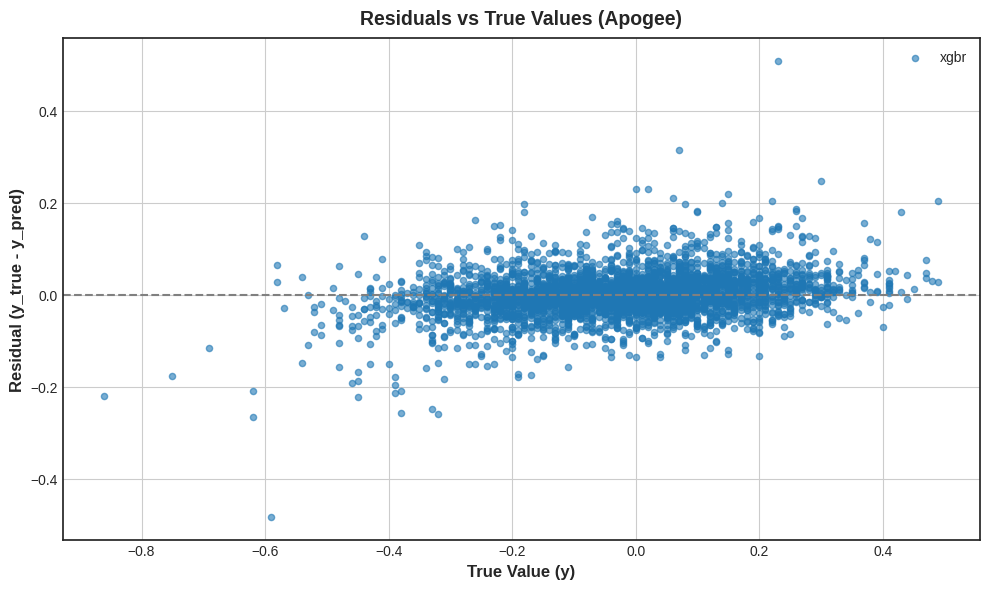

In [289]:
# Example for one model and one test set
best_model_name = 'xgbr'
model_xgbr = model_names[best_model_name]
model_xgbr.fit(X_apogee_train, y_apogee_train)

y_pred_apogee_xgbr = model_xgbr.predict(X_apogee_test)
plot_residuals_vs_true(y_apogee_test, y_pred_apogee_xgbr, model_name=best_model_name, sample_name='Apogee')

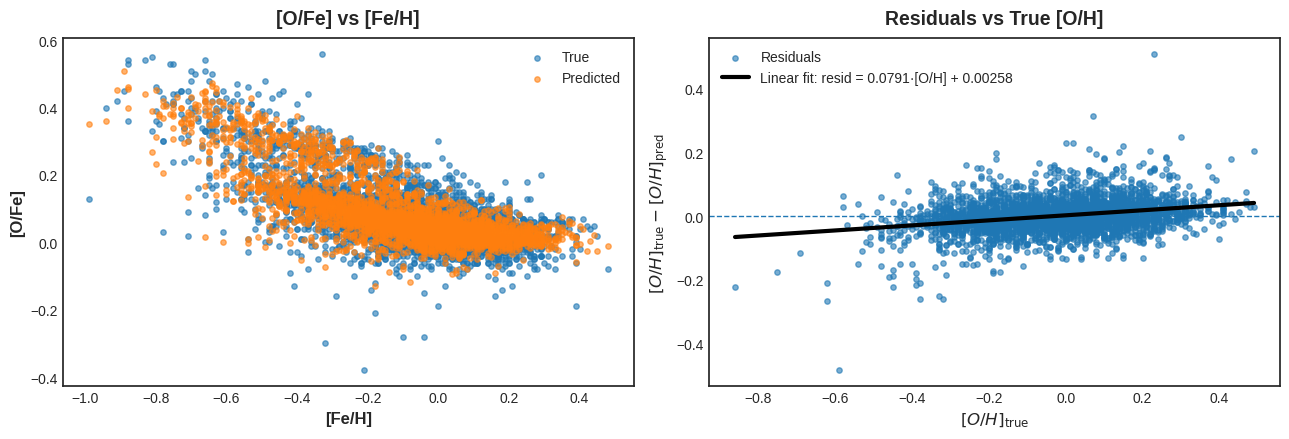

In [290]:
import numpy as np
import matplotlib.pyplot as plt

# --- Inputs assumed:
# X_apogee_test: DataFrame with column "fe_h" (=[Fe/H])
# y_apogee_test: Series/array with true [O/H]
# y_pred_apogee_xgbr: array with predicted [O/H]

feh = X_apogee_test["fe_h"].to_numpy()
y_true = np.asarray(y_apogee_test)
y_pred = np.asarray(y_pred_apogee_xgbr)

# Residuals: true - pred
resid = y_true - y_pred

# Left panel: [O/Fe] = [O/H] - [Fe/H]
ofe_true = y_true - feh
ofe_pred = y_pred - feh

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

# -------------------------
# Left: [O/Fe] vs [Fe/H]
# -------------------------
axes[0].scatter(feh, ofe_true, s=15, alpha=0.6, label="True")
axes[0].scatter(feh, ofe_pred, s=15, alpha=0.6, label="Predicted")

axes[0].set_xlabel("[Fe/H]")
axes[0].set_ylabel("[O/Fe]")
axes[0].set_title("[O/Fe] vs [Fe/H]")
axes[0].legend()

# -------------------------
# Right: residuals vs y_true with linear fit
# -------------------------
axes[1].scatter(y_true, resid, s=15, alpha=0.6, label="Residuals")
axes[1].axhline(0, linestyle="--", linewidth=1)

# Linear fit: resid = a*y_true + b
a, b = np.polyfit(y_true, resid, 1)
xfit = np.linspace(np.nanmin(y_true), np.nanmax(y_true), 200)
yfit = a * xfit + b
axes[1].plot(xfit, yfit, linewidth=3, color = 'black', label=f"Linear fit: resid = {a:.3g}·[O/H] + {b:.3g}")

axes[1].set_xlabel(r"$[O/H]_{\rm true}$")
axes[1].set_ylabel(r"$[O/H]_{\rm true} - [O/H]_{\rm pred}$")
axes[1].set_title("Residuals vs True [O/H]")
axes[1].legend()

plt.tight_layout()
plt.show()
